# A tour of `chladni.geometry`

`chladni` computes Laplacian eigenvalues of planar domains by a GSVD-regularized Method of
Particular Solutions. This notebook tours its first layer — the geometry — which is what the
eigensolver will be built on top of.

There is no eigensolver yet, so nothing here touches one. The tour ends instead on the
primitives the solver layers will consume: boundary quadrature with provenance, corner data
carrying boundary conditions, and a masked grid ready for an eigenfunction.

Everything below uses only public API.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt

import chladni.geometry as G
from chladni.geometry import (ArcSegment, Boundary, Domain, LineSegment, Panel,
                              Polygon, legendre_nodes)
from chladni.plotting import (field_grid, plot_diagnostic, plot_domain,
                              plot_normals, plot_tangents)

plt.rcParams.update({"figure.dpi": 90, "figure.constrained_layout.use": True, "font.size": 9})
print(f"{len(G.__all__)} public names in chladni.geometry")

28 public names in chladni.geometry


## 1. Three ways to build a domain

A `Domain` is an outer `Boundary` — a closed, contiguous chain of `Segment`s — plus any
number of holes. You can take one from the library, hand `Polygon` a list of vertices, or
assemble segments yourself.

Polygon(area=3)
Polygon(area=3)
Domain(area=2.7854)


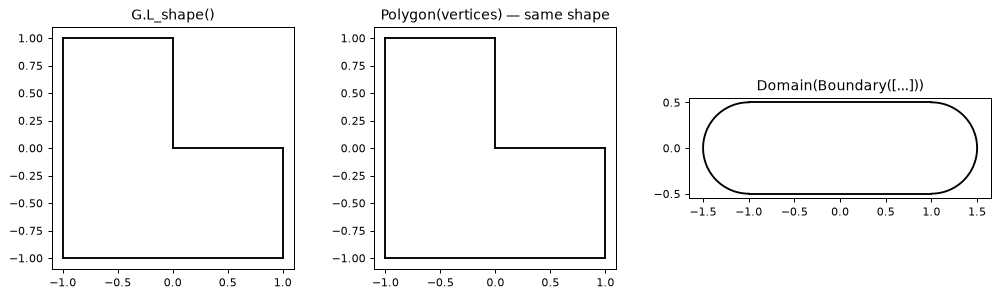

In [2]:
lib = G.L_shape()
poly = Polygon([0, 1j, -1 + 1j, -1 - 1j, 1 - 1j, 1])   # the same shape, by hand
stadium = Domain(Boundary([
    LineSegment(-1 - 0.5j, 1 - 0.5j),
    ArcSegment(1 + 0j, 0.5, -np.pi / 2, np.pi / 2),
    LineSegment(1 + 0.5j, -1 + 0.5j),
    ArcSegment(-1 + 0j, 0.5, np.pi / 2, 3 * np.pi / 2),
]))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, d, title in zip(axes, [lib, poly, stadium],
                        ["G.L_shape()", "Polygon(vertices) — same shape", "Domain(Boundary([...]))"]):
    plot_domain(d, ax=ax)
    ax.set_title(title)
    ax.set_aspect("equal")

for d in (lib, poly, stadium):
    print(d)

## 2. Segments, and why `tau` is arclength

Every segment carries whatever native parameter it was built with, but exposes a
**normalized arclength parameter** `tau` in $[0,1]$ as the public one. That means
$|dp/d\tau| = \text{length}$ identically — the curve is traversed at constant speed.

The difference is visible. Below, 25 points at equal `tau` against 25 at equal native $t$ on
the same ellipse: the native parameter bunches them at the ends of the major axis.

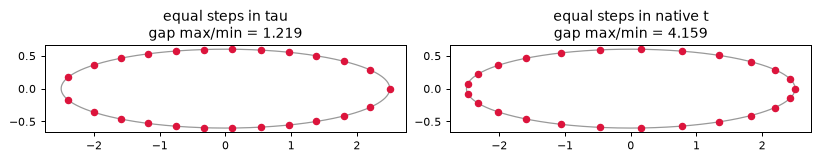

In [3]:
A, B = 2.5, 0.6
ellipse = G.ParametricSegment(lambda t: A * np.cos(t) + 1j * B * np.sin(t),
                              lambda t: -A * np.sin(t) + 1j * B * np.cos(t), 0, 2 * np.pi)

tau = np.linspace(0, 1, 25, endpoint=False)
by_tau = ellipse.p(tau)                                            # equal arclength
by_t = A * np.cos(2 * np.pi * tau) + 1j * B * np.sin(2 * np.pi * tau)   # equal native t
dense = ellipse.p(np.linspace(0, 1, 600))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.0))
for ax, z, title in zip(axes, [by_tau, by_t], ["equal steps in tau", "equal steps in native t"]):
    gaps = np.abs(np.diff(np.append(z, z[0])))
    ax.plot(dense.real, dense.imag, "-", color="0.6", lw=1)
    ax.plot(z.real, z.imag, "o", ms=5, color="crimson")
    ax.set_title(f"{title}\ngap max/min = {gaps.max() / gaps.min():.3f}")
    ax.set_aspect("equal")

That constant-speed property is not approximate. It holds by construction: the arclength map
solves $s(t)=s$ by Newton, so $t'(s) = 1/|p'(t)|$ analytically and
$dp/d\tau = p'(t)\,L/|p'(t)|$ has modulus $L$ exactly.

Every boundary quadrature in the library rests on this.

In [4]:
err = np.abs(np.abs(ellipse.dp(np.linspace(0, 1, 401))) - ellipse.length).max()
print(f"max | |dp(tau)| - length |  over 401 points:  {err:.2e}")
assert err < 1e-12

from scipy.special import ellipe
exact = 4 * A * ellipe(1 - (B / A) ** 2)
print(f"ellipse perimeter: {ellipse.length:.12f}   4a·E(m) = {exact:.12f}")
assert abs(ellipse.length - exact) < 1e-10

max | |dp(tau)| - length |  over 401 points:  3.55e-15
ellipse perimeter: 10.677401453655   4a·E(m) = 10.677401453655


Four segment types share that interface. A `SplineSegment` also reports its knots as
`break_taus`, because a cubic spline is only $C^2$ there and a quadrature panel must break
at them or lose spectral convergence.

spline knots, in tau: [0.23524 0.51222 0.77533]


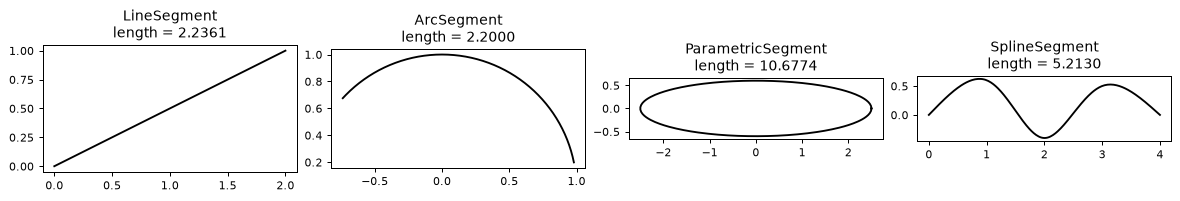

In [5]:
segments = {
    "LineSegment": LineSegment(0j, 2 + 1j),
    "ArcSegment": ArcSegment(0j, 1.0, 0.2, 2.4),
    "ParametricSegment": ellipse,
    "SplineSegment": G.SplineSegment.interp_from_pts([0, 1 + 0.6j, 2 - 0.4j, 3 + 0.5j, 4 + 0j]),
}

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, (name, s) in zip(axes, segments.items()):
    s.plot(ax=ax)
    ax.set_title(f"{name}\nlength = {s.length:.4f}")
    ax.set_aspect("equal")

print("spline knots, in tau:", np.round(segments["SplineSegment"].break_taus, 5))

## 3. Orientation and frames

Outer boundaries run counter-clockwise and holes clockwise. Under that convention the
outward unit normal is simply $N = -i\,T$ on *every* boundary, with no special case for
holes — and signed areas add, so a hole's clockwise loop subtracts its own area.

as built:  orientation +1,  signed area +3.000000
reversed:  orientation -1,  signed area -3.000000


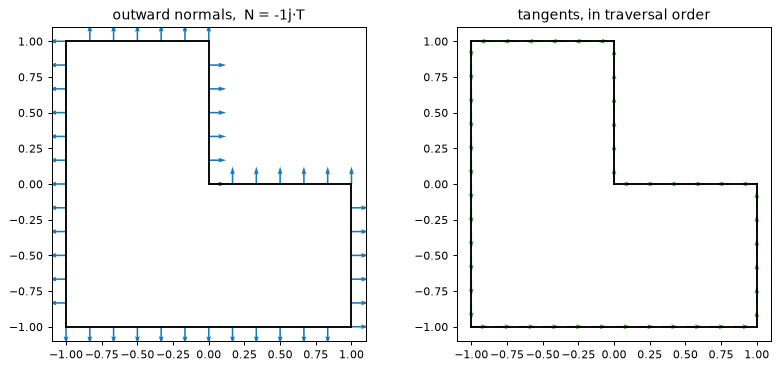

In [6]:
d = G.L_shape()

fig, axes = plt.subplots(1, 2, figsize=(9, 4.0))
plot_domain(d, ax=axes[0])
plot_normals(d, n=48, ax=axes[0], color="tab:blue", width=0.005)
axes[0].set_title("outward normals,  N = -1j·T")
plot_domain(d, ax=axes[1])
plot_tangents(d, n=48, ax=axes[1], color="tab:green", width=0.005)
axes[1].set_title("tangents, in traversal order")
for ax in axes:
    ax.set_aspect("equal")

b = d.outer
print(f"as built:  orientation {b.orientation:+d},  signed area {b.signed_area:+.6f}")
print(f"reversed:  orientation {b.reversed().orientation:+d},  signed area {b.reversed().signed_area:+.6f}")

seg = b.segments[0]
t = np.linspace(0, 1, 7)
assert np.allclose(seg.N(t), -1j * seg.T(t))

## 4. Corners

A `Corner` is an object, not a row in a set of parallel arrays. It carries the interior
angle, the boundary conditions on *both* sides, its clearance, a branch-cut direction, and
references to its two adjacent segments.

Two things about corner detection are easy to get wrong, and both are visible below.

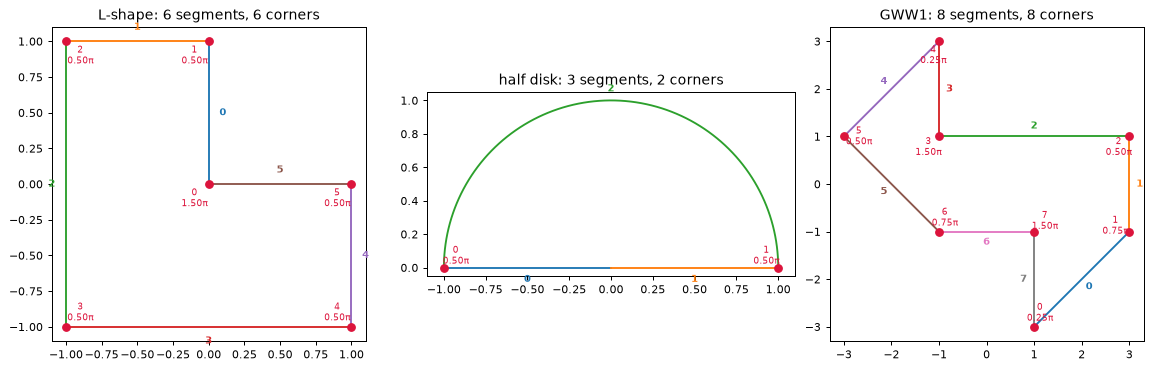

In [7]:
half_disk = Domain(Boundary([
    LineSegment(-1 + 0j, 0j),
    LineSegment(0j, 1 + 0j),
    ArcSegment(0j, 1.0, 0.0, np.pi),
]))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
for ax, d, title in zip(axes, [G.L_shape(), half_disk, G.GWW1()],
                        ["L-shape", "half disk", "GWW1"]):
    plot_diagnostic(d, ax=ax)
    ax.set_title(f"{title}: {len(d.outer.segments)} segments, {len(d.corners)} corners")
    ax.set_aspect("equal")

**The half disk has three segments but two corners.** Its two radial pieces are collinear, so
the junction at the origin has interior angle exactly $\pi$ and is not a corner at all. Keeping
corner-indexed and segment-indexed data in separate arrays is how that shape becomes a bug.

The second trap runs the other way: a corner does not have to be geometric. Where a Dirichlet
edge meets a Neumann edge the solution is singular even if the boundary is perfectly straight,
because the singularity exponent depends on the boundary-condition pair as well as the angle.

z =         0j   omega = 0.50π   geometric=True  bc_junction=True  singular=True
z =   (0.5+0j)   omega = 1.00π   geometric=False bc_junction=True  singular=True
z =     (1+0j)   omega = 0.50π   geometric=True  bc_junction=True  singular=True
z =     (1+1j)   omega = 0.50π   geometric=True  bc_junction=False singular=True
z =         1j   omega = 0.50π   geometric=True  bc_junction=True  singular=True

1 singular corner with interior angle exactly pi, at z = (0.5+0j)


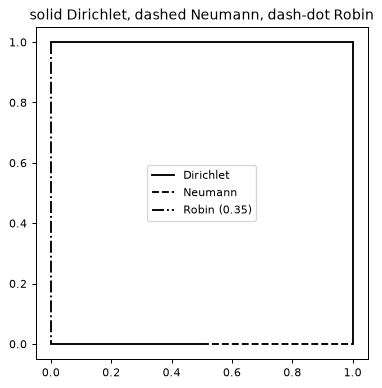

In [8]:
mixed = Domain(Boundary([
    LineSegment(0j, 0.5 + 0j, bc="dir"),
    LineSegment(0.5 + 0j, 1 + 0j, bc="neu"),
    LineSegment(1 + 0j, 1 + 1j), LineSegment(1 + 1j, 1j),
    LineSegment(1j, 0j, bc=0.35),
]))

for c in mixed.corners:
    print(f"z = {str(c.z):>10s}   omega = {c.omega/np.pi:.2f}π   geometric={c.is_geometric!s:<5s} "
          f"bc_junction={c.is_bc_junction!s:<5s} singular={c.is_singular}")

straight = [c for c in mixed.corners if c.is_bc_junction and not c.is_geometric]
print(f"\n{len(straight)} singular corner with interior angle exactly pi, at z = {straight[0].z}")
assert straight[0].omega == np.pi and straight[0].is_singular

fig, ax = plt.subplots(figsize=(4.2, 4.2))
plot_domain(mixed, ax=ax, show_bc=True, legend=True)
ax.set_title("solid Dirichlet, dashed Neumann, dash-dot Robin")
ax.set_aspect("equal")

## 5. Clearance and branch cuts

Two more purely geometric facts the solver needs at each corner.

**Clearance** is the distance to the nearest non-adjacent piece of boundary — a proxy for the
largest disk about the corner that stays inside the domain, which bounds how far a local
corner expansion stays valid, and therefore how long a corner-anchored quadrature panel may be.

**The branch cut.** A corner-adapted expansion carries $r^{k\pi/\omega}$, which for fractional
exponent needs a branch cut, and the cut must not pass through the domain.

z =         0j  omega = 1.50π  clearance = 1.0000  adjacent edge = 1.00
z =         1j  omega = 0.50π  clearance = 1.0000  adjacent edge = 1.00
z =    (-1+1j)  omega = 0.50π  clearance = 1.0000  adjacent edge = 2.00
z =    (-1-1j)  omega = 0.50π  clearance = 1.4142  adjacent edge = 2.00
z =     (1-1j)  omega = 0.50π  clearance = 1.0000  adjacent edge = 1.00
z =     (1+0j)  omega = 0.50π  clearance = 1.0000  adjacent edge = 1.00


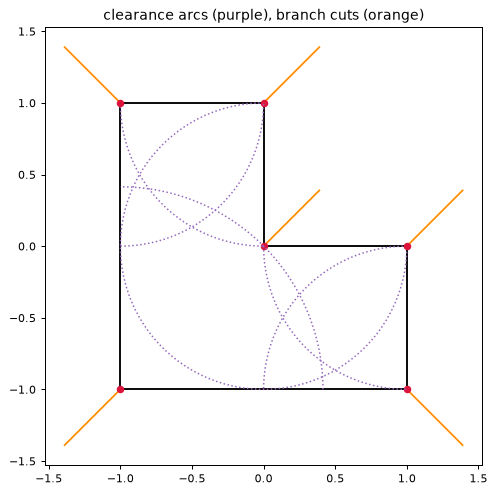

In [9]:
from matplotlib.patches import Circle

d = G.L_shape()
fig, ax = plt.subplots(figsize=(5.4, 5.4))
plot_domain(d, ax=ax)
for c in d.corners:
    # only the part of the clearance circle inside the corner's own wedge: clearance
    # ignores the two ADJACENT segments, so the full circle would leave the domain
    a0 = np.angle(c.t_out)
    arc = c.z + c.clearance * np.exp(1j * np.linspace(a0, a0 + c.omega, 80))
    ax.plot(arc.real, arc.imag, ":", color="tab:purple", lw=1.2)
    path = c.branch_path(0.55)
    ax.plot(path.real, path.imag, "-", color="darkorange", lw=1.4)
    ax.plot(c.z.real, c.z.imag, "o", color="crimson", ms=5)
ax.set_title("clearance arcs (purple), branch cuts (orange)")
ax.set_aspect("equal")

for c in d.corners:
    print(f"z = {str(c.z):>10s}  omega = {c.omega/np.pi:.2f}π  clearance = {c.clearance:.4f}  "
          f"adjacent edge = {c.segment_out.length:.2f}")

Sometimes no straight ray escapes. On a spiral the inner coils *surround* corners: their
exterior is a channel that turns, so a ray in any direction eventually re-enters the domain.
Those corners get a wall-following polyline cut instead — offset the boundary outward, walk
along it until reaching a point that can see infinity, then attach a ray there.

12 of 24 corners need a wall-followed polyline cut
vertices per walked cut: [1, 2, 3, 4, 5, 6]


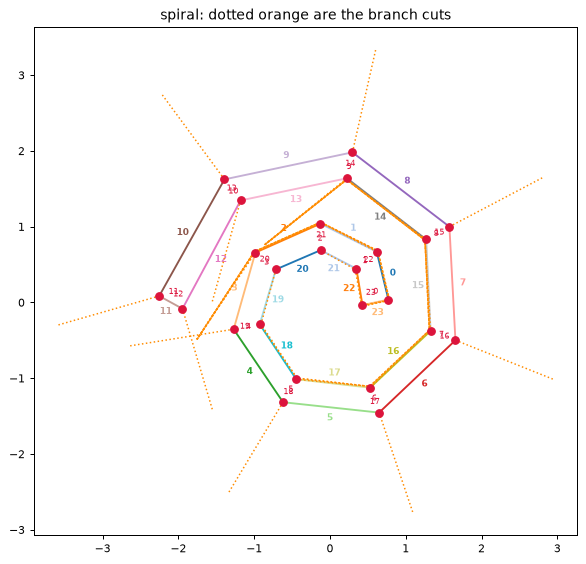

In [10]:
sp = G.spiral()
fig, ax = plt.subplots(figsize=(6.4, 6.4))
plot_diagnostic(sp, ax=ax, branch_cuts=True, labels=False, fontsize=6)
ax.set_title("spiral: dotted orange are the branch cuts")
ax.set_aspect("equal")

walked = [c for c in sp.corners if c.branch_vertices]
print(f"{len(walked)} of {len(sp.corners)} corners need a wall-followed polyline cut")
print("vertices per walked cut:", sorted({len(c.branch_vertices) for c in walked}))
assert all(c.admits_exterior_branch_cut for c in sp.corners)

## 6. Metrics, against closed forms

Area, perimeter, diameter, inradius and centroid. Area comes from a boundary integral (exact
on a polygon, spectral on a curve), the diameter refines a sampled maximum on the true curve,
and the inradius is a compass search on the distance-to-boundary function.

In [11]:
import math

rows = [
    ("square",      G.rect(1, 1),   1.0,                4.0,        math.sqrt(2),     0.5),
    ("eq triangle", G.eq_tri(1),    math.sqrt(3) / 4,   3.0,        1.0,              1 / (2 * math.sqrt(3))),
    ("unit disk",   G.disk(1),      math.pi,            2 * math.pi, 2.0,             1.0),
    ("hexagon",     G.reg_ngon(6),  3 * math.sqrt(3) / 2, 6.0,      2.0,              math.cos(math.pi / 6)),
    ("L-shape",     G.L_shape(),    3.0,                8.0,        2 * math.sqrt(2), 2 - math.sqrt(2)),
]

hdr = f"{'domain':12s}{'area':>26s}{'perimeter':>26s}{'diameter':>26s}{'inradius':>26s}"
print(hdr); print("-" * len(hdr))
for name, d, a, p, dia, r in rows:
    print(f"{name:12s}"
          f"{d.area:13.9f}/{a:12.9f}"
          f"{d.perimeter:13.9f}/{p:12.9f}"
          f"{d.diameter:13.9f}/{dia:12.9f}"
          f"{d.inradius:13.9f}/{r:12.9f}")
    assert abs(d.area - a) < 1e-8 and abs(d.perimeter - p) < 1e-8
    assert abs(d.diameter - dia) < 1e-7 and abs(d.inradius - r) < 1e-7

domain                            area                 perimeter                  diameter                  inradius
--------------------------------------------------------------------------------------------------------------------
square        1.000000000/ 1.000000000  4.000000000/ 4.000000000  1.414213562/ 1.414213562  0.500000000/ 0.500000000
eq triangle   0.433012702/ 0.433012702  3.000000000/ 3.000000000  1.000000000/ 1.000000000  0.288675135/ 0.288675135
unit disk     3.141592654/ 3.141592654  6.283185307/ 6.283185307  2.000000000/ 2.000000000  1.000000000/ 1.000000000
hexagon       2.598076211/ 2.598076211  6.000000000/ 6.000000000  2.000000000/ 2.000000000  0.866025404/ 0.866025404
L-shape       3.000000000/ 3.000000000  8.000000000/ 8.000000000  2.828427125/ 2.828427125  0.585786438/ 0.585786438


The L-shape's inradius is worth a second look: it is $2-\sqrt2 = 0.5858$, **not** $\tfrac12$.
The largest inscribed disk is not the one that fits across an arm — it sits on the diagonal,
pinned by the reentrant corner.

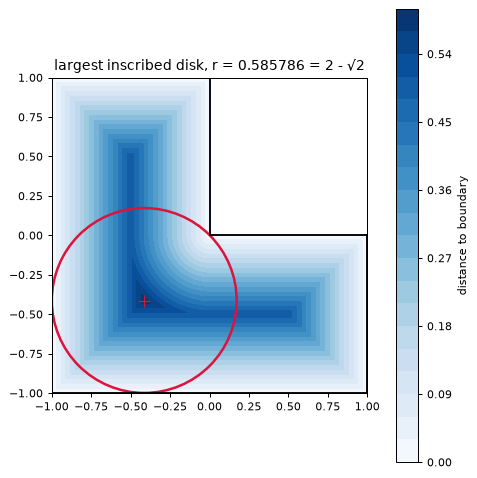

In [12]:
d = G.L_shape()
lo, hi = d.bbox
gx = np.linspace(lo.real, hi.real, 400)
gy = np.linspace(lo.imag, hi.imag, 400)
X, Y = np.meshgrid(gx, gy)
inside = d.contains((X + 1j * Y).ravel()).reshape(X.shape)
dist = np.where(inside, d.boundary_distance((X + 1j * Y).ravel()).reshape(X.shape), np.nan)
centre = (X + 1j * Y).ravel()[np.nanargmax(np.where(inside, dist, -1).ravel())]

fig, ax = plt.subplots(figsize=(5.2, 5.2))
cs = ax.contourf(X, Y, dist, levels=20, cmap="Blues")
plot_domain(d, ax=ax, fill=False)
ax.add_patch(Circle((centre.real, centre.imag), d.inradius, fill=False, ec="crimson", lw=2))
ax.plot(centre.real, centre.imag, "+", color="crimson", ms=10)
fig.colorbar(cs, ax=ax, label="distance to boundary")
ax.set_title(f"largest inscribed disk, r = {d.inradius:.6f} = 2 - √2")
ax.set_aspect("equal")

## 7. Domains with holes

Holes were designed in from the start. `fill` shades the domain so an outline is never
ambiguous about which side is $\Omega$ — and because holes wind clockwise, the fill rule
punches them out with no special-casing.

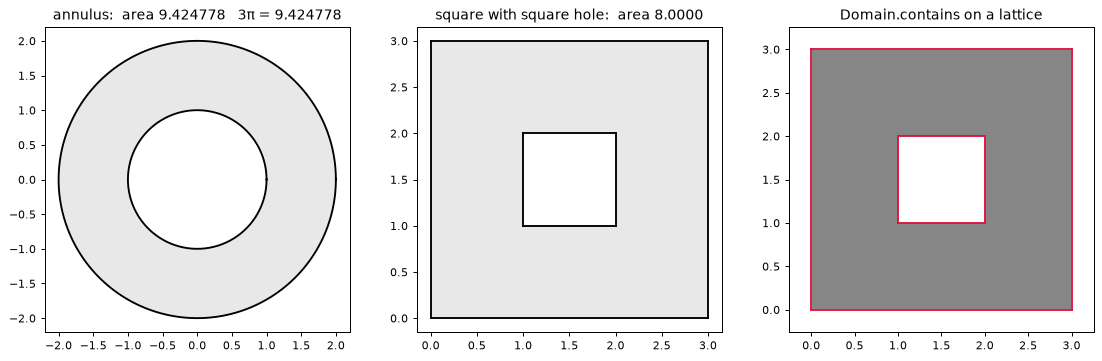

In [13]:
ann = G.annulus(2.0, 1.0)
holed = Domain(Boundary.from_vertices([0, 3, 3 + 3j, 3j]),
               holes=(Boundary.from_vertices([1 + 1j, 2 + 1j, 2 + 2j, 1 + 2j]).reversed(),))

g = np.linspace(-0.25, 3.25, 240)
X, Y = np.meshgrid(g, g)
inside = holed.contains((X + 1j * Y).ravel()).reshape(X.shape)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9))
plot_domain(ann, ax=axes[0])
axes[0].set_title(f"annulus:  area {ann.area:.6f}   3π = {3*np.pi:.6f}")
plot_domain(holed, ax=axes[1])
axes[1].set_title(f"square with square hole:  area {holed.area:.4f}")
axes[2].pcolormesh(X, Y, inside.astype(float), cmap="Greys", shading="auto", vmin=0, vmax=1.8)
plot_domain(holed, ax=axes[2], fill=False, color="crimson")
axes[2].set_title("Domain.contains on a lattice")
for ax in axes:
    ax.set_aspect("equal")

assert abs(ann.area - 3 * np.pi) < 1e-8 and abs(holed.area - 8.0) < 1e-12

Holes change what a corner can do. A loop in $\Omega$ encircling a hole also winds around
every point of that hole's boundary, so the angle measured from a corner *on* the hole gains
$2\pi$ around it. Killing that loop needs a cut joining the hole to the outer boundary — which
must cross $\Omega$. The obstruction is topological, so `admits_exterior_branch_cut` is False
there and the diagnostic draws those corners open rather than filled.

Note also that a convex hole corner is **reentrant** from the domain's side: $\omega$ measures
the wedge of $\Omega$, not of the hole.

z =         0j  bdry 0  on_hole=False omega = 0.50π  admits_cut=True
z =     (3+0j)  bdry 0  on_hole=False omega = 0.50π  admits_cut=True
z =     (3+3j)  bdry 0  on_hole=False omega = 0.50π  admits_cut=True
z =         3j  bdry 0  on_hole=False omega = 0.50π  admits_cut=True
z =     (1+1j)  bdry 1  on_hole=True  omega = 1.50π  admits_cut=False
z =     (1+2j)  bdry 1  on_hole=True  omega = 1.50π  admits_cut=False
z =     (2+2j)  bdry 1  on_hole=True  omega = 1.50π  admits_cut=False
z =     (2+1j)  bdry 1  on_hole=True  omega = 1.50π  admits_cut=False


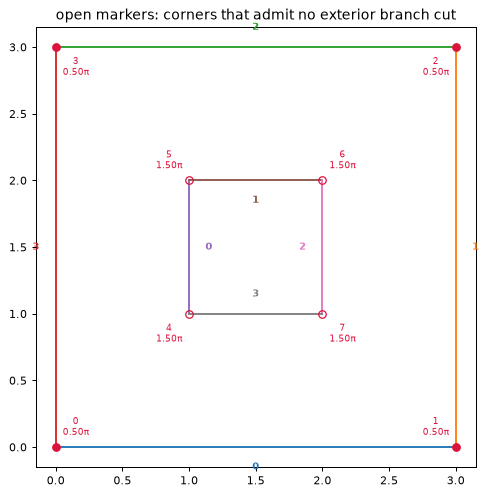

In [14]:
fig, ax = plt.subplots(figsize=(5.4, 5.4))
plot_diagnostic(holed, ax=ax)
ax.set_title("open markers: corners that admit no exterior branch cut")
ax.set_aspect("equal")

for c in holed.corners:
    print(f"z = {str(c.z):>10s}  bdry {c.bdry_idx}  on_hole={c.on_hole!s:<5s} "
          f"omega = {c.omega/np.pi:.2f}π  admits_cut={c.admits_exterior_branch_cut}")

## 8. Boundary quadrature

`Domain.bdry_quad(n)` returns a `Quadrature`: nodes, **weights**, frames, and each node's
provenance — which boundary, which segment, and where along it. Weights matter; a rule that
returns only points cannot be used for the boundary integrals the eigensolver needs.

In [15]:
d = G.L_shape()
q = d.bdry_quad(400)

print(f"{len(q)} nodes, weight_family = {q.weight_family!r}")
print(f"wts.sum()  = {q.wts.sum():.12f}")
print(f"perimeter  = {d.perimeter:.12f}")
print(f"provenance: seg_idx {np.unique(q.seg_idx)}, bdry_idx {np.unique(q.bdry_idx)}, "
      f"tau in [{q.tau.min():.3f}, {q.tau.max():.3f}]")
assert abs(q.wts.sum() - d.perimeter) < 1e-8

400 nodes, weight_family = 'arclength'
wts.sum()  = 8.000000000000
perimeter  = 8.000000000000
provenance: seg_idx [0 1 2 3 4 5], bdry_idx [0], tau in [0.001, 0.999]


A live self-check. The divergence theorem gives $\oint_{\partial\Omega}(x-x_0)\cdot n\,ds =
2|\Omega|$ for **any** base point $x_0$, and it ties the nodes, the normals and the weights
together against an independently known area. It is also exactly the integrand shape the
Rellich identity uses. It holds across holes too, which it would not if a hole's normals
pointed the wrong way.

In [16]:
for dom, name in [(d, "L-shape"), (ann, "annulus"), (holed, "square with hole")]:
    qq = dom.bdry_quad(1200)
    for x0 in (0j, 1 + 1j, -4 + 3j):
        val = (qq.radial(x0) * qq.wts).sum()
        assert abs(val - 2 * dom.area) < 1e-6
    print(f"{name:20s} ∮(x-x0)·n ds = {val:.10f}   2|Ω| = {2*dom.area:.10f}")

L-shape              ∮(x-x0)·n ds = 6.0000000000   2|Ω| = 6.0000000000
annulus              ∮(x-x0)·n ds = 18.8495559215   2|Ω| = 18.8495559215
square with hole     ∮(x-x0)·n ds = 16.0000000000   2|Ω| = 16.0000000000


On an analytic boundary the rule converges spectrally — the error falls faster than any power
of the node count, reaching machine precision by about 24 nodes on a disk.

{4: '1.4e-02', 6: '2.3e-03', 8: '1.7e-04', 10: '7.8e-06', 12: '2.4e-07', 16: '1.7e-11', 20: '6.3e-14', 24: '1.1e-14', 32: '2.1e-14', 48: '1.8e-15'}


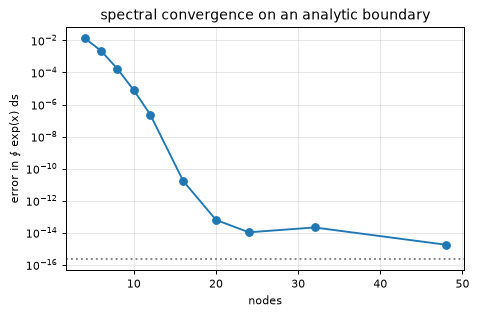

In [17]:
D = G.disk()
exact = 2 * np.pi * float(np.i0(1.0))          # ∮ exp(x) ds on the unit circle
ns = np.array([4, 6, 8, 10, 12, 16, 20, 24, 32, 48])
errs = np.array([abs(D.bdry_quad(int(n)).integrate(lambda z: np.exp(z.real)) - exact) for n in ns])

fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.semilogy(ns, np.maximum(errs, 1e-17), "o-")
ax.axhline(np.finfo(float).eps, ls=":", color="0.5")
ax.set_xlabel("nodes"); ax.set_ylabel("error in ∮ exp(x) ds")
ax.set_title("spectral convergence on an analytic boundary")
ax.grid(alpha=0.3)
print(dict(zip(ns.tolist(), [f"{e:.1e}" for e in errs])))

Panels break at every corner and at every spline knot. They can also be *graded* — clustered
towards a corner, which is where a singular eigenfunction needs the resolution. The effect is
real but small enough that you have to zoom in to see it.

grading keeps the weight sum exact: 8.000000000000 vs 8.000000000000


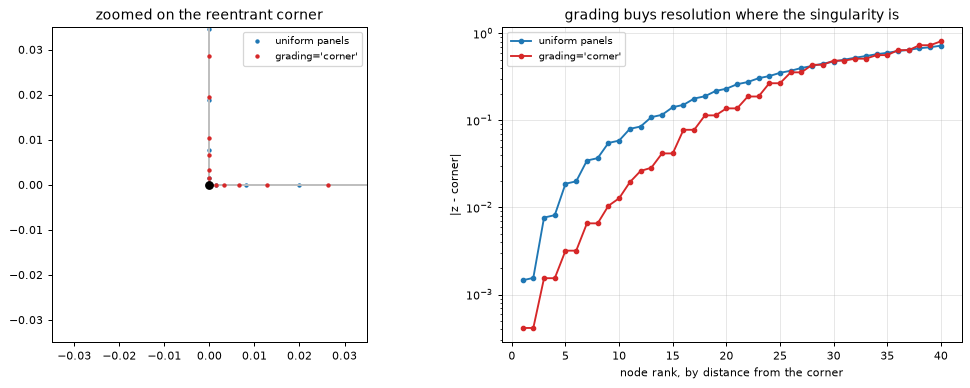

In [18]:
d = G.L_shape()
corner = next(c for c in d.corners if c.is_reentrant).z
plain = d.bdry_quad(240)
graded = d.bdry_quad(240, grading="corner")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for q, colour, title in [(plain, "tab:blue", "uniform panels"),
                         (graded, "tab:red", "grading='corner'")]:
    plot_domain(d, ax=axes[0], fill=False, color="0.75")
    axes[0].plot(q.pts.real, q.pts.imag, ".", ms=5, color=colour, label=title)
    ranked = np.sort(np.abs(q.pts - corner))[:40]
    axes[1].semilogy(np.arange(1, len(ranked) + 1), ranked, "o-", ms=3.5,
                     color=colour, label=title)

axes[0].plot(corner.real, corner.imag, "o", color="k", ms=6)
axes[0].set_xlim(corner.real - 0.035, corner.real + 0.035)
axes[0].set_ylim(corner.imag - 0.035, corner.imag + 0.035)
axes[0].set_aspect("equal")
axes[0].set_title("zoomed on the reentrant corner")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("node rank, by distance from the corner")
axes[1].set_ylabel("|z - corner|")
axes[1].set_title("grading buys resolution where the singularity is")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

print(f"grading keeps the weight sum exact: {graded.wts.sum():.12f} vs {d.perimeter:.12f}")
assert abs(graded.wts.sum() - d.perimeter) < 1e-8

## 9. Bringing your own quadrature rule

The eigensolver will need corner-adapted Gauss–Jacobi rules keyed to the singularity exponent
$\nu = \pi/\omega$. Geometry does not know $\nu$ and does not compute it — but it does hand out
the seam, so the layer above never has to redo node placement, the panel map, the frames or the
boundary-condition tagging by hand.

A plan is a list of `Panel`s, each naming its boundary, segment, span in `tau`, and a callable
producing nodes and weights. Weights come back **in `tau`**, and geometry only multiplies by
the segment length to turn $d\tau$ into $ds$: rescaling a singular weight onto a shorter panel
picks up a power of the panel width set by that weight's own homogeneity, and only the layer
that chose the weight knows the exponent.

204 nodes over 12 panels, family 'arclength'
weights still sum to the perimeter: 8.000000000000 vs 8.000000000000
a rule that is NOT plain arclength declares itself: 'even'


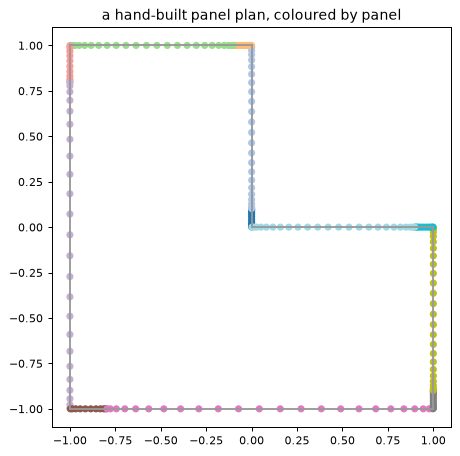

In [19]:
d = G.L_shape()

plan = []
for i in range(len(d.outer.segments)):
    plan.append(Panel(bdry_idx=0, seg_idx=i, tau0=0.0, tau1=0.10, nodes=legendre_nodes(10)))
    plan.append(Panel(bdry_idx=0, seg_idx=i, tau0=0.10, tau1=1.0, nodes=legendre_nodes(24)))

q = d.bdry_quad(panels=plan)
print(f"{len(q)} nodes over {len(np.unique(q.panel_id))} panels, family {q.weight_family!r}")
print(f"weights still sum to the perimeter: {q.wts.sum():.12f} vs {d.perimeter:.12f}")
assert abs(q.wts.sum() - d.perimeter) < 1e-9

singular = d.bdry_quad(panels=plan, weight_family="even")
print(f"a rule that is NOT plain arclength declares itself: {singular.weight_family!r}")

fig, ax = plt.subplots(figsize=(5.0, 5.0))
plot_domain(d, ax=ax, fill=False, color="0.6")
ax.scatter(q.pts.real, q.pts.imag, c=q.panel_id, cmap="tab20", s=22)
ax.set_title("a hand-built panel plan, coloured by panel")
ax.set_aspect("equal")

`weight_family` exists so the object never makes a claim something else contradicts. For the
plain family `integrate(f)` is $\oint f\,ds$ and the weights sum to the perimeter; for a
singular family the weights absorb a weight function $w$, `integrate(f)` is $\oint f w\,ds$,
and they sum to $\oint w\,ds$ instead.

## 10. Transforms, immutability, and precision

Geometry objects are immutable. Every transform returns a new object, which is what makes
`prec` a fixed attribute rather than a cache key — a fixed object's cached approximations can
never be stale. Operators are sugar for the transforms.

original untouched: area 3.000000
area scales as s²:  12.000000 = 4 × 3.000000
assignment refused: Polygon is immutable; use a transform (translated/rotated/scaled/reversed/with_bc/with_prec) to get a new object


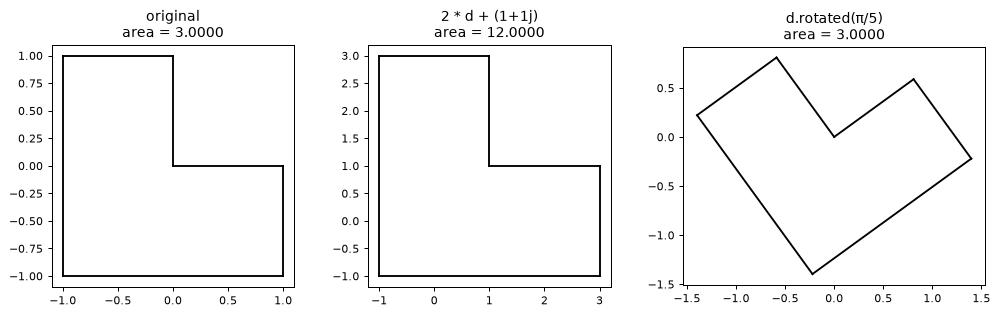

In [20]:
d = G.L_shape()
moved = 2 * d + (1 + 1j)         # scale then translate
turned = d.rotated(np.pi / 5)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, dom, title in zip(axes, [d, moved, turned],
                          ["original", "2 * d + (1+1j)", "d.rotated(π/5)"]):
    plot_domain(dom, ax=ax)
    ax.set_title(f"{title}\narea = {dom.area:.4f}")
    ax.set_aspect("equal")

print(f"original untouched: area {d.area:.6f}")
print(f"area scales as s²:  {moved.area:.6f} = 4 × {d.area:.6f}")
try:
    d.outer = None
except AttributeError as exc:
    print(f"assignment refused: {exc}")

`prec` is the working relative precision, default `1e-8`. It is not decoration — every
adaptive approximation is derived from it.

One configuration defeats it, and for arithmetic reasons rather than implementation ones: a
feature of size $h$ sitting at coordinate $R$ from the origin resolves to about
$\varepsilon R/h$. A domain says so itself rather than quietly returning worse numbers than
asked for.

In [21]:
tiny = G.L_shape().scaled(1e-4)
print(f"small but centred:  achievable_prec = {tiny.achievable_prec:.2e}   (prec = {tiny.prec:.0e})")

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    far = G.L_shape().scaled(1e-4).translated(1e6)

print(f"small and far away: achievable_prec = {far.achievable_prec:.2e}")
print()
print(f"{caught[0].category.__name__}: {caught[0].message}")

small but centred:  achievable_prec = 6.28e-16   (prec = 1e-08)
small and far away: achievable_prec = 7.85e-07



## 11. The primitive an eigenfunction plot will use

`field_grid` returns `(X, Y, mask)` over the domain's bounding box, masked to $\Omega$ — holes
excluded, since it goes through `Domain.contains`.

There is no eigensolver yet, so the field plotted below is a stand-in: distance to the
boundary. When the solver lands, the only line that changes is the one computing the values.

grid (320, 320), 56392 points inside the domain of 102400


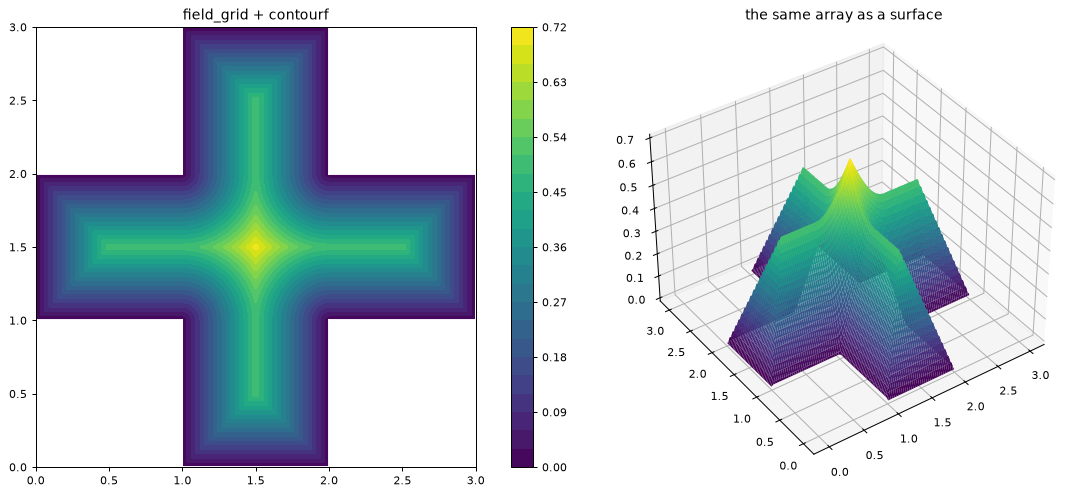

In [22]:
d = G.plus_shape()
X, Y, mask = field_grid(d, n=320)

# stand-in for an eigenfunction: u(x) = distance to the boundary
values = d.boundary_distance((X + 1j * Y).ravel()).reshape(X.shape)
u = np.where(mask, values, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
cs = axes[0].contourf(X, Y, u, levels=24, cmap="viridis")
plot_domain(d, ax=axes[0], fill=False, color="w", linewidth=1.5)
fig.colorbar(cs, ax=axes[0])
axes[0].set_title("field_grid + contourf")
axes[0].set_aspect("equal")

axes[1].remove()
ax3d = fig.add_subplot(1, 2, 2, projection="3d")
ax3d.plot_surface(X, Y, u, cmap="viridis", linewidth=0, antialiased=True,
                  rstride=3, cstride=3)
ax3d.view_init(elev=38, azim=-125)
ax3d.set_title("the same array as a surface")

print(f"grid {X.shape}, {mask.sum()} points inside the domain of {mask.size}")

## 12. The library

Every shipped domain, drawn the same way. `polyomino` builds the boundary of any edge-connected
set of unit cells and merges collinear runs, so a straight side is one segment rather than
several joined by smooth junctions.

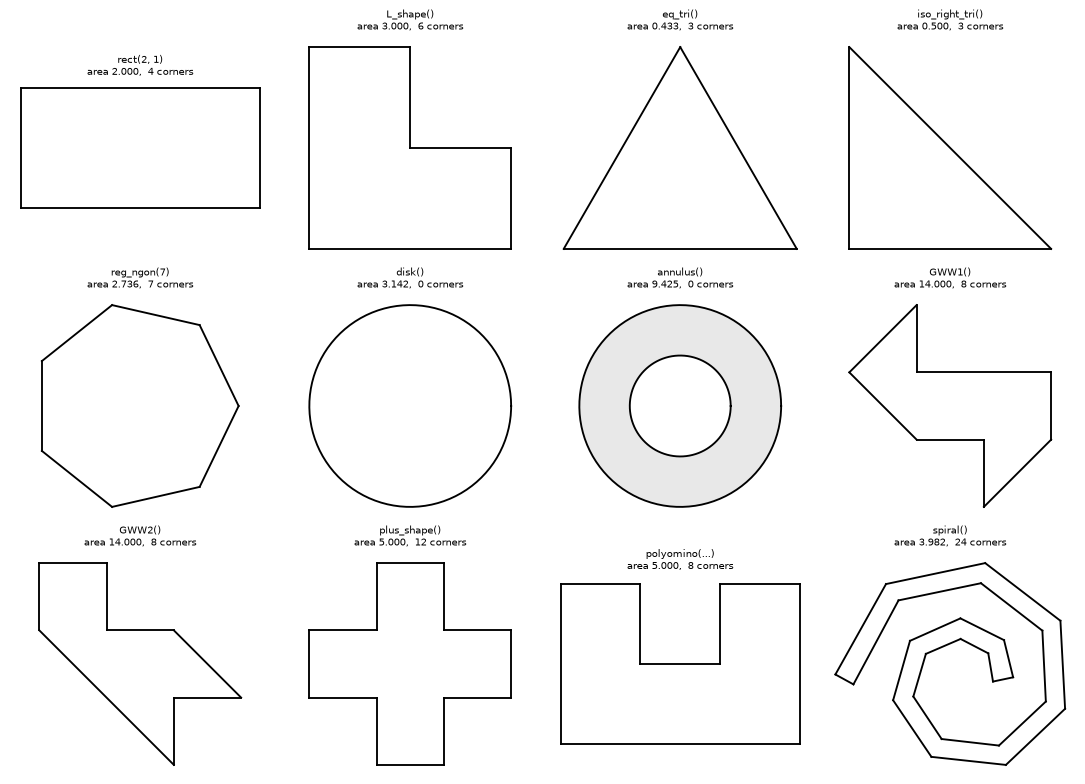

In [23]:
factories = [
    ("rect(2, 1)", lambda: G.rect(2, 1)),      ("L_shape()", G.L_shape),
    ("eq_tri()", G.eq_tri),                    ("iso_right_tri()", G.iso_right_tri),
    ("reg_ngon(7)", lambda: G.reg_ngon(7)),    ("disk()", G.disk),
    ("annulus()", G.annulus),                  ("GWW1()", G.GWW1),
    ("GWW2()", G.GWW2),                        ("plus_shape()", G.plus_shape),
    ("polyomino(...)", lambda: G.polyomino([(0, 0), (1, 0), (2, 0), (2, 1), (0, 1)])),
    ("spiral()", G.spiral),
]

fig, axes = plt.subplots(3, 4, figsize=(12, 8.6))
for ax, (name, make) in zip(axes.ravel(), factories):
    dom = make()
    plot_domain(dom, ax=ax)
    ax.set_title(f"{name}\narea {dom.area:.3f},  {len(dom.corners)} corners", fontsize=8)
    ax.set_aspect("equal")
    ax.axis("off")

### Where this goes next

`GWW1` and `GWW2` above are the Gordon–Webb–Wolpert isospectral pair: different shapes, same
Laplacian spectrum. They share an area of 14 and a perimeter of $12+6\sqrt2$ — the first two
terms of the Weyl asymptotic — which is a useful check on a solver long before it can tell
them apart, since it never can.

The next layer up builds particular solutions of the Helmholtz equation on this geometry:
corner-adapted fractional-order Fourier–Bessel functions anchored at the corners of
section 4, using the angles, the boundary-condition pairs, the clearances and the branch cuts.
Then the MPS eigensolver assembles them against the boundary quadrature of section 8.